# Polarization ray tracing with coatings

`raytrace.System.trace_polarization()` follows the **polarization** and the
**power** of every ray through a system: each surface multiplies the field
with Chipman's $3\times3$ polarization ray tracing matrix

$$P = t_s\,\hat s\hat s^T + t_p\,\hat p'\hat p^T,$$

whose Fresnel coefficients come from the bare interface or from the thin
film stack (`coatings.Coating`) on the surface, evaluated at the local angle
of incidence of the ray. Mirrors reflect through their coating on a
substrate, and the media between the surfaces can absorb
(`materials.Isotropic`, $n + ik$) or be birefringent and dichroic
(`materials.Uniaxial`, `materials.CubicCrystal`).

This notebook coats Caldwell's all fused silica KrF lens (248.3 nm, NA 0.56,
42 surfaces) with realistic DUV antireflection coatings and looks at:

1. the angles of incidence in the lens and the design of a two layer AR
   coating from fluoride materials,
2. the energy budget of the lens (reflection and absorption losses through
   the pupil and surface by surface),
3. the polarization the coatings leave in the Jones pupil (diattenuation,
   retardance),
4. layer thickness variations across strongly curved surfaces,
5. a protected aluminium fold mirror.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

from pyoptics.coatings import Coating, Layer, RadialProfile
from pyoptics.litho import jones_pupil as jp
from pyoptics.litho.plot import plot_orientation
from pyoptics.raytrace import CoordinateBreak, Rays, Surface, System, caldwell_krf_lens

plt.rcParams.update({"figure.dpi": 100, "font.size": 11})

## 1. Coating materials at 248 nm

Few coating materials are transparent enough for KrF. Production DUV AR
coatings are built from fluorides, typically MgF$_2$ as the low index
material and LaF$_3$ (or GdF$_3$) as the high index material; oxides like
Al$_2$O$_3$ are used as well, while HfO$_2$ and TiO$_2$ absorb too much.
Typical indices of evaporated films at 248 nm are (order of magnitude for
the extinction, which depends strongly on the deposition process):

| material | $n$ | $k$ |
|---|---|---|
| MgF$_2$ | 1.42 | $\sim 10^{-4}$ |
| LaF$_3$ | 1.69 | $\sim 3\cdot10^{-4}$ |
| fused silica (substrate) | 1.508 | $\approx 0$ |

The extinction coefficients make the coatings absorb a few $10^{-4}$ of
the light at every surface, which adds up over 42 surfaces and is part of
the energy budget below. Indices are given as complex numbers $n + ik$ with
$k > 0$ (the pyoptics convention $\exp(i(\mathbf k\cdot\mathbf r - \omega t))$).

In [2]:
system = caldwell_krf_lens()
wl = system.wavelength  # mm
n_glass = system.n[1]
MgF2, LaF3 = 1.42 + 1e-4j, 1.69 + 3e-4j
print("wavelength {:.1f} nm, fused silica n = {:.4f}".format(system.wavelength_nm, n_glass))

wavelength 248.3 nm, fused silica n = 1.5084


### Angles of incidence in the lens

The coating has to work over the angles of incidence that occur in the lens.
We trace a grid of pupil rays at the centre and at the edge of the field and
collect the angle between ray and local surface normal at every surface:

median 8.0 deg, 99th percentile 28.5 deg, max 41.1 deg


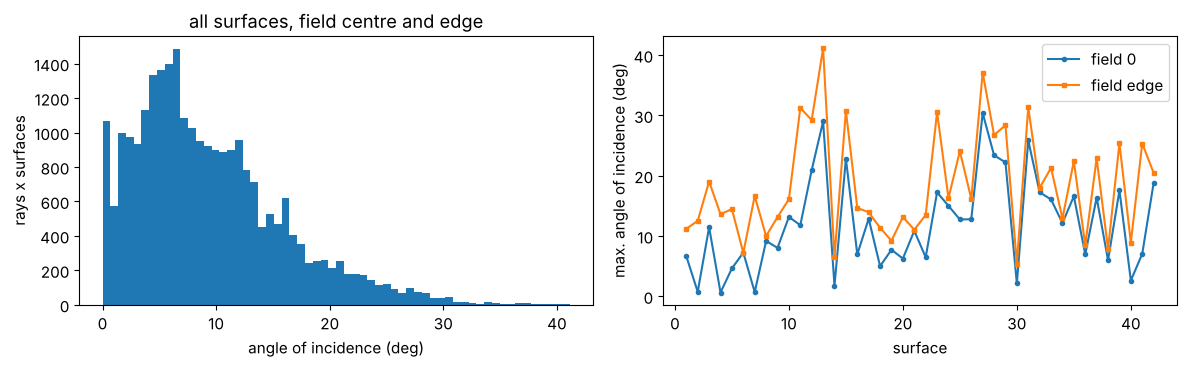

In [3]:
def angles_of_incidence(system, field, N=21):
    p = np.linspace(-1, 1, N)
    PX, PY = np.meshgrid(p, p)
    inside = PX**2 + PY**2 <= 1
    bundle = system.trace_pupil(field, PX[inside], PY[inside])
    frames = system.frames()[0]
    aoi = []
    for i, s in enumerate(system.surfaces):
        o, R = frames[i]
        ok = bundle.valid
        Q = (bundle.points[i + 1][ok] - o) @ R
        cos_i = np.abs(np.sum(s.normal(Q)*(bundle.directions[i][ok] @ R), axis=-1))
        aoi.append(np.degrees(np.arccos(np.clip(cos_i, 0, 1))))
    return aoi

aoi = angles_of_incidence(system, 0.0) + angles_of_incidence(system, system.max_field)
aoi_all = np.concatenate(aoi)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].hist(aoi_all, bins=60, color="C0")
axes[0].set_xlabel("angle of incidence (deg)"), axes[0].set_ylabel("rays x surfaces")
axes[0].set_title("all surfaces, field centre and edge")
n_s = len(system.surfaces)
axes[1].plot(np.arange(1, n_s + 1), [a.max() for a in aoi[:n_s]], "o-", ms=3, label="field 0")
axes[1].plot(np.arange(1, n_s + 1), [a.max() for a in aoi[n_s:]], "s-", ms=3, label="field edge")
axes[1].set_xlabel("surface"), axes[1].set_ylabel("max. angle of incidence (deg)")
axes[1].legend()
plt.tight_layout()
print("median {:.1f} deg, 99th percentile {:.1f} deg, max {:.1f} deg".format(
    *np.percentile(aoi_all, [50, 99, 100])))

### Single layer versus two layer AR coating

A quarter wave of MgF$_2$ (as in the Jones pupil notebook) would need
$n = \sqrt{1.508} = 1.23$ for zero reflection; with the real $n = 1.42$ it
leaves about 2 % per surface. A **two layer coating** (air | MgF$_2$ |
LaF$_3$ | glass) works with real materials and comes close to zero over a range of angles. We optimize the two thicknesses for the smallest mean reflectance
(s and p averaged) between 0° and 35°, the range that holds nearly all rays
of the lens.

In [4]:
angles = np.radians(np.linspace(0, 35, 36))

def mean_R(coating):
    p = coating.power(angles, 1.0, n_glass, wl)
    return np.mean((p["R_s"] + p["R_p"])/2)

def two_layer(d_MgF2, d_LaF3):  # thicknesses in nm, layers from the air side
    return Coating([Layer(MgF2, d_MgF2*1e-6, label="MgF2"), Layer(LaF3, d_LaF3*1e-6, label="LaF3")])

single = Coating([Layer.quarter_wave(MgF2, wl, label="MgF2")])
best = min((minimize(lambda d: mean_R(two_layer(*d)), d0, method="Nelder-Mead")
            for d0 in [(44, 37), (44, 74), (60, 30)]), key=lambda r: r.fun)
d_MgF2, d_LaF3 = best.x
vcoat = two_layer(d_MgF2, d_LaF3)
print("single layer: MgF2 {:.1f} nm, mean R = {:.2%}".format(single.layers[0].thickness*1e6,
                                                            mean_R(single)))
print("two layer:    MgF2 {:.1f} nm, LaF3 {:.1f} nm, mean R = {:.3%}".format(d_MgF2, d_LaF3,
                                                                          mean_R(vcoat)))

single layer: MgF2 43.7 nm, mean R = 2.13%
two layer:    MgF2 45.0 nm, LaF3 37.6 nm, mean R = 0.151%


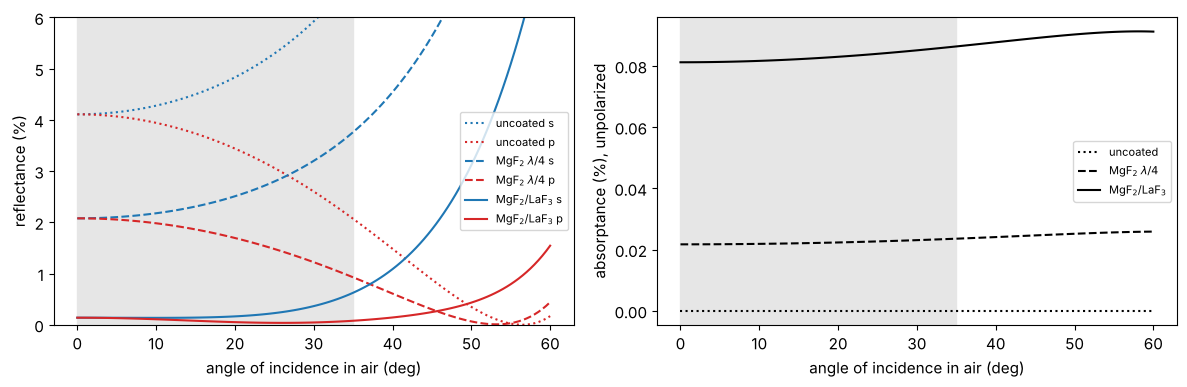

In [5]:
theta = np.radians(np.linspace(0, 60, 121))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
bare = Coating()
for c, name, ls in ((bare, "uncoated", ":"), (single, "MgF$_2$ $\\lambda/4$", "--"),
                    (vcoat, "MgF$_2$/LaF$_3$", "-")):
    p = c.power(theta, 1.0, n_glass, wl)
    for pol, color in (("s", "C0"), ("p", "C3")):
        axes[0].plot(np.degrees(theta), 100*p["R_" + pol], ls=ls, color=color,
                     label="{} {}".format(name, pol))
    axes[1].plot(np.degrees(theta), 100*(p["A_s"] + p["A_p"])/2, ls=ls, color="k", label=name)
axes[0].set_ylim(0, 6), axes[0].set_ylabel("reflectance (%)")
axes[1].set_ylabel("absorptance (%), unpolarized")
for ax in axes:
    ax.axvspan(0, 35, color="0.9", zorder=0)
    ax.set_xlabel("angle of incidence in air (deg)")
    ax.legend(fontsize=8)
plt.tight_layout()

The two layer coating keeps the reflectance below a few tenths of a percent
up to about 35° (grey), at the price of a small absorption in the LaF$_3$
layer. Beyond the design range the reflectance rises quickly, and s and p
separate: this is where the coating creates diattenuation.

## 2. Coating the lens

The coating is attached to every glass–air surface. The layers of a
`Coating` are listed in the order the light meets them, so on the exit
surfaces of the lens elements (glass → air) the stack is `reversed()`.

In [6]:
def coat(system, coating, profile=None):
    # a copy of the system with the coating on every glass-air surface
    coated = system.copy()
    n = coated.n
    for i, s in enumerate(coated.surfaces):
        if n[i] == n[i + 1]:
            continue
        c = coating if profile is None else profile(s, coating)
        s.coating = c if n[i] < n[i + 1] else c.reversed()
    return coated

variants = {"uncoated": system, "MgF2 single layer": coat(system, single),
            "MgF2/LaF3": coat(system, vcoat)}

p = np.linspace(-1, 1, 41)
PX, PY = np.meshgrid(p, p)
inside = PX**2 + PY**2 <= 1
traced = {name: s.trace_pupil_polarization(0.0, PX[inside], PY[inside])
          for name, s in variants.items()}
for name, t in traced.items():
    T = t.transmittance()
    print("{:18s} transmittance: centre {:.3f}, mean {:.3f}, min {:.3f}".format(
        name, T[np.argmin(PX[inside]**2 + PY[inside]**2)], np.nanmean(T), np.nanmin(T)))

uncoated           transmittance: centre 0.172, mean 0.172, min 0.172
MgF2 single layer  transmittance: centre 0.410, mean 0.410, min 0.408
MgF2/LaF3          transmittance: centre 0.912, mean 0.916, min 0.912


### Transmission over the pupil

The transmittance of the rays is the apodization of the lens, here for
unpolarized light. The uncoated lens transmits only 17 %, the single layer
41 % and the two layer coating 91 %. Across the pupil it varies by less than
1 % (note the colour scales): for unpolarized light the losses of s and p
change in opposite directions with the angle of incidence and nearly cancel.
The difference between s and p shows up in the Jones pupil (section 3).

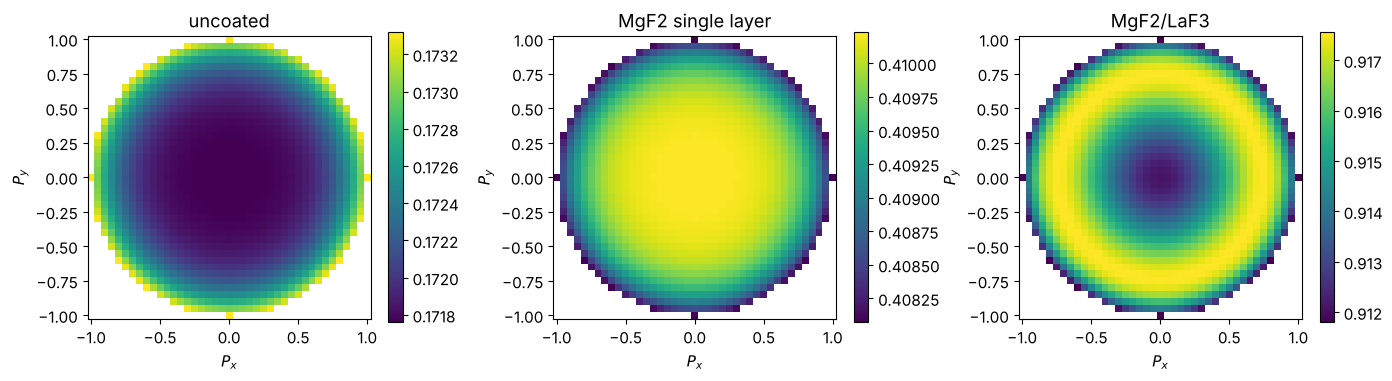

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (name, t) in zip(axes, traced.items()):
    T = np.full(PX.shape, np.nan)
    T[inside] = t.transmittance()
    im = ax.pcolormesh(p, p, T, shading="auto", cmap="viridis")
    ax.set_aspect("equal"), ax.set_title(name)
    ax.set_xlabel("$P_x$"), ax.set_ylabel("$P_y$")
    plt.colorbar(im, ax=ax, shrink=0.85)
plt.tight_layout()

### Energy budget surface by surface

`PolarizedBundle.power()` gives the power that is left behind every
surface. For the chief ray and a marginal ray of the coated lens, the steps
are the reflection and absorption losses of the individual surfaces.
Comparing with the lossless coating (the same layers with $k = 0$) separates
the two:

chief ray: transmitted 0.912, reflected 0.056, absorbed 0.032
marginal ray: transmitted 0.912, reflected 0.056, absorbed 0.032


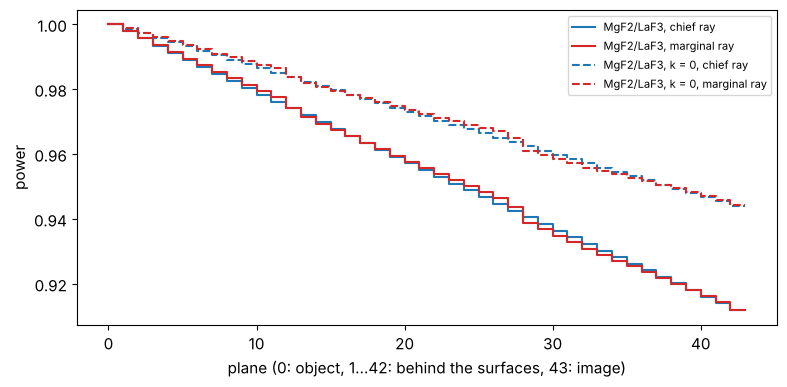

In [8]:
lossless = two_layer(d_MgF2, d_LaF3)
for layer in lossless.layers:
    layer.material = layer.material.real
rays = (0.0, [0.0, 0.0], [0.0, 1.0])  # chief and marginal ray at field 0
power = {name: s.trace_pupil_polarization(*rays).power()
         for name, s in (("MgF2/LaF3", variants["MgF2/LaF3"]),
                         ("MgF2/LaF3, k = 0", coat(system, lossless)))}

fig, ax = plt.subplots(figsize=(8, 4))
planes = np.arange(power["MgF2/LaF3"].shape[0])
for (name, P), ls in zip(power.items(), ("-", "--")):
    ax.step(planes, P[:, 0], where="post", ls=ls, color="C0", label=name + ", chief ray")
    ax.step(planes, P[:, 1], where="post", ls=ls, color="C3", label=name + ", marginal ray")
ax.set_xlabel("plane (0: object, 1...42: behind the surfaces, 43: image)")
ax.set_ylabel("power")
ax.legend(fontsize=8)
plt.tight_layout()
T, T0 = power["MgF2/LaF3"][-1], power["MgF2/LaF3, k = 0"][-1]
print("chief ray: transmitted {:.3f}, reflected {:.3f}, absorbed {:.3f}".format(T[0], 1 - T0[0],
                                                                            T0[0] - T[0]))
print("marginal ray: transmitted {:.3f}, reflected {:.3f}, absorbed {:.3f}".format(T[1], 1 - T0[1],
                                                                               T0[1] - T[1]))

(The split is approximate: the lossless stack also reflects slightly
differently.) With these extinction coefficients the absorption of the
coatings is of the same order as their residual reflection, which is why
coating absorption (and its heating of the lens, *lens heating*) matters in
DUV lithography.

## 3. Polarization: the Jones pupil

`PolarizedBundle.jones()` returns the Jones matrices between the aplanatic
bases of the object and image space rays; `jones_pupil.decompose()` splits
them into transmission, scalar phase, linear diattenuation and linear
retardance (orientators: magnitude and axis). The maps use the entrance pupil
coordinates of the rays:

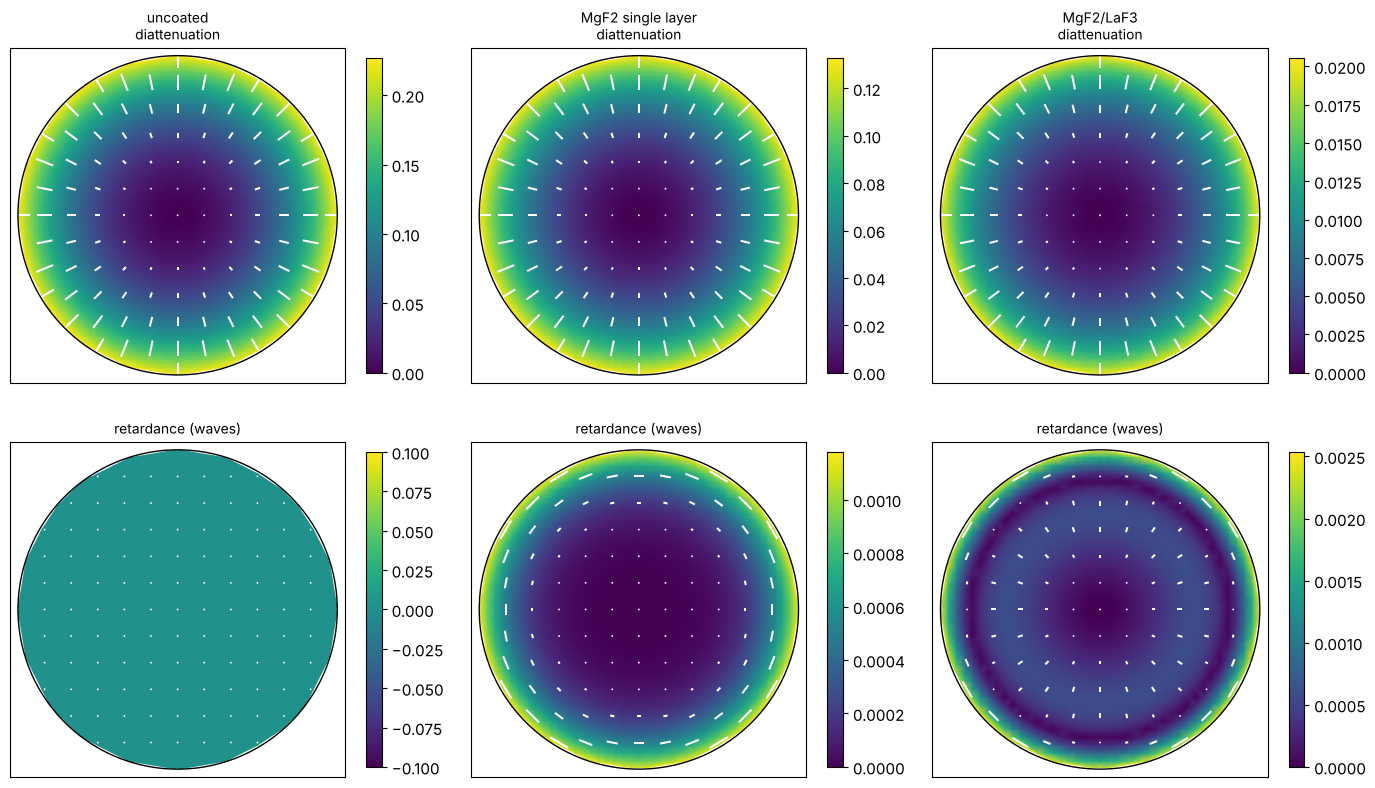

In [9]:
fig, axes = plt.subplots(2, 3, figsize=(14, 8.4))
for col, (name, t) in enumerate(traced.items()):
    ok = t.valid
    parts = jp.decompose(t.jones()[ok])
    d, g = parts["diattenuation"], parts["retardance"]
    xy = (PX[inside][ok], PY[inside][ok])
    plot_orientation(xy + (d[0] + 1j*d[1],), ax=axes[0, col], title=name + "\ndiattenuation")
    plot_orientation(xy + (g[0] + 1j*g[1],), ax=axes[1, col], title="retardance (waves)")
plt.tight_layout()

The uncoated lens is a radial diattenuator with no retardance (real Fresnel
coefficients). Both coatings reduce the diattenuation strongly, but add
retardance that grows towards the rim of the pupil, since the phases of
$t_s$ and $t_p$ of a thin film stack separate with the angle of incidence.
The two layer coating has the smaller diattenuation and a retardance of
some thousandths of a wave.

## 4. Layer thickness variations on curved surfaces

In an evaporation plant the layers grow thinner towards the rim of a
strongly curved lens, roughly with the cosine of the local slope angle of
the surface, $t(r) \approx t_0 \cos\alpha(r)$ with
$\sin\alpha = r/R$ for a sphere. To second order this is
$t/t_0 \approx 1 - \tfrac12 (r/R)^2$, a `RadialProfile` with
$a_2 = -\tfrac12 (r_\mathrm{max}/R)^2$ on $\rho = r/r_\mathrm{max}$. The
profile is evaluated at the hit point of every ray in the local surface
coordinates.

strongest thinning at the rim: surface 39: -26%, surface 11: -25%, surface 27: -25%, surface 40: -20%, surface 32: -18%


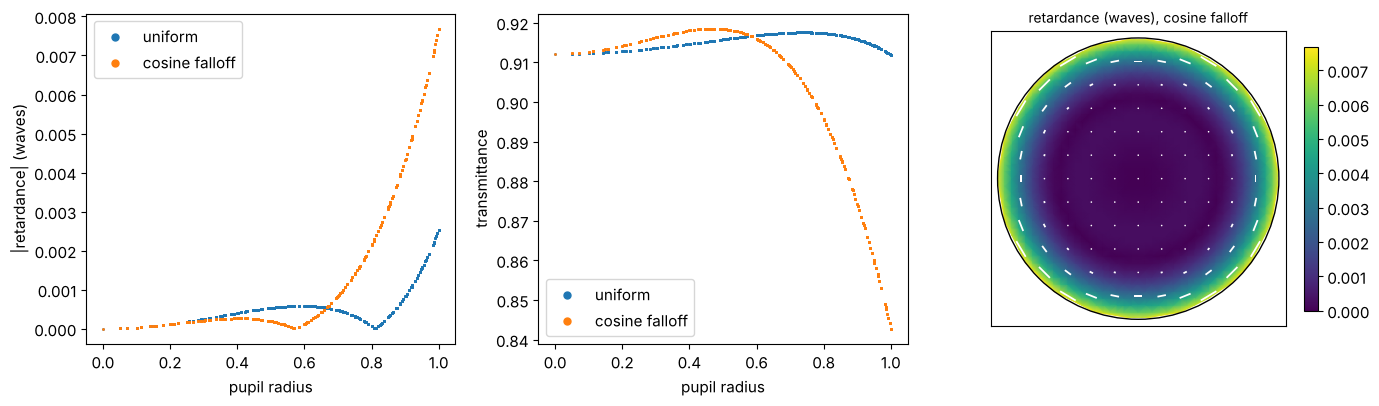

In [10]:
def cosine_falloff(surface, coating):
    r_max = surface.semi_diameter
    a2 = -0.5*(r_max/surface.R)**2 if np.isfinite(surface.R) else 0.0
    return Coating([Layer(l.material, l.thickness, RadialProfile([a2], r_norm=r_max), l.label)
                    for l in coating.layers])

profiled = coat(system, vcoat, profile=cosine_falloff)
rim = sorted(((-0.5*(s.semi_diameter/s.R)**2, i + 1) for i, s in enumerate(system.surfaces)))[:5]
print("strongest thinning at the rim:",
      ", ".join("surface {}: {:.0%}".format(i, a) for a, i in rim))

t_prof = profiled.trace_pupil_polarization(0.0, PX[inside], PY[inside])
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
results = {}
for name, t in (("uniform", traced["MgF2/LaF3"]), ("cosine falloff", t_prof)):
    ok = t.valid
    parts = jp.decompose(t.jones()[ok])
    results[name] = t, ok, parts
    g = parts["retardance"]
    rho = np.hypot(PX[inside][ok], PY[inside][ok])
    axes[0].plot(rho, np.hypot(*g[:2]), ".", ms=2, label=name)
    axes[1].plot(rho, t.transmittance()[ok], ".", ms=2, label=name)
axes[0].set_ylabel("|retardance| (waves)"), axes[1].set_ylabel("transmittance")
for ax in axes[:2]:
    ax.set_xlabel("pupil radius"), ax.legend(markerscale=5)
t, ok, parts = results["cosine falloff"]
g = parts["retardance"]
plot_orientation((PX[inside][ok], PY[inside][ok], g[0] + 1j*g[1]), ax=axes[2],
                 title="retardance (waves), cosine falloff")
plt.tight_layout()

Thinner layers shift the reflectance minimum of the coating to shorter
wavelengths, which at a fixed wavelength acts like a larger angle of
incidence: the transmission at the rim of the pupil drops and the
retardance changes. Uniformity masks in the coating plant are used to keep
such profiles within specification; with `RadialProfile`,
`PolynomialProfile` or `ZernikeProfile` (or any function of the local
$x, y$) measured or modelled profiles go straight into the ray trace.

## 5. A protected aluminium fold mirror

Folded lens designs (catadioptric lithography lenses) use fold mirrors at
large angles of incidence. Bare aluminium oxidizes, so it is protected by a
dielectric overcoat, here MgF$_2$. Aluminium at 248 nm has
$n \approx 0.19 + 2.94i$ (Rakić, Appl. Opt. 34, 4755 (1995)). The coating of a
mirror lists its layers from the incidence side and names the substrate:

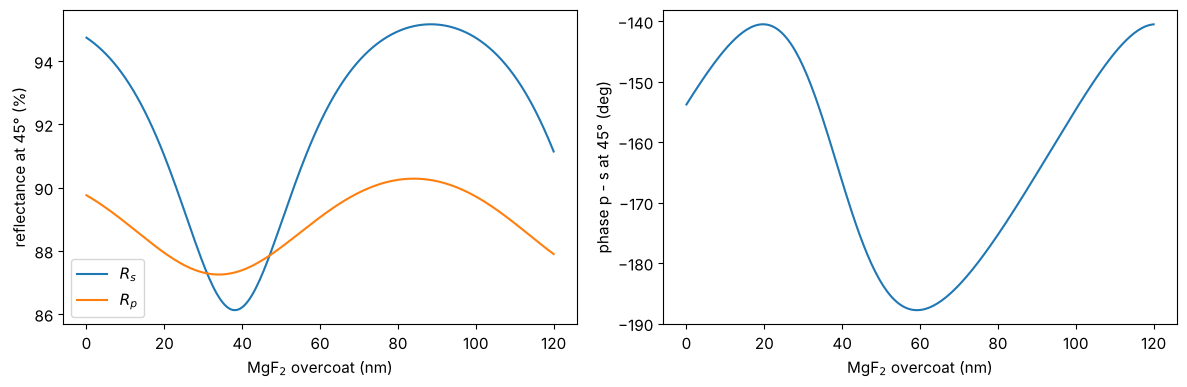

In [11]:
Al = 0.19 + 2.94j
d = np.linspace(0, 120, 241)  # MgF2 overcoat thickness in nm
R_s, R_p, delta = [], [], []
for di in d:
    c = Coating([Layer(MgF2, di*1e-6)], substrate=Al)
    p = c.power(np.pi/4, 1.0, wavelength=wl)
    r_s, r_p = c.amplitudes(np.cos(np.pi/4), 1.0, None, wl)[:2]
    R_s.append(p["R_s"]), R_p.append(p["R_p"])
    delta.append(np.angle(-r_p/r_s))  # phase of p relative to s (full field)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(d, 100*np.array(R_s), label="$R_s$")
axes[0].plot(d, 100*np.array(R_p), label="$R_p$")
axes[0].set_ylabel("reflectance at 45° (%)")
axes[1].plot(d, np.degrees(np.unwrap(delta)))
axes[1].set_ylabel("phase p - s at 45° (deg)")
for ax in axes:
    ax.set_xlabel("MgF$_2$ overcoat (nm)")
axes[0].legend()
plt.tight_layout()

The overcoat changes reflectance and retardance of the mirror periodically
with its optical thickness. In a system, the mirror is a `Surface(mirror=True,
coating=...)`. Here a collimated beam is folded by 90° about the x axis
with coordinate breaks; the Jones matrix of the chief ray is diagonal in
s ($x$) and p, with the retardance and diattenuation of the coating:

In [12]:
protected = Coating([Layer(MgF2, 25e-6, label="MgF2")], substrate=Al)
fold = System([Surface(thickness=10.0, semi_diameter=10.0),
               CoordinateBreak(tilt=(np.pi/4, 0, 0)),
               Surface(mirror=True, coating=protected),
               CoordinateBreak(tilt=(np.pi/4, 0, 0), thickness=-10.0)], 0, wl)
t = fold.trace_polarization(Rays([[0.0, 0.0, -1.0]], [[0.0, 0.0, 1.0]], [0.0]))
J = t.jones()[0]
parts = jp.decompose(J)
print("Jones matrix of the fold:\n", np.round(J, 4))
print("power: s {:.4f}, p {:.4f}, unpolarized {:.4f}".format(
    t.transmittance((1, 0))[0], t.transmittance((0, 1))[0], t.transmittance()[0]))
print("diattenuation {:.4f}, retardance {:.4f} waves".format(
    np.hypot(*parts["diattenuation"][:2]), np.hypot(*parts["retardance"][:2])))

Jones matrix of the fold:
 [[0.2653-0.9071j 0.    +0.j    ]
 [0.    +0.j     0.7575-0.5493j]]
power: s 0.8932, p 0.8756, unpolarized 0.8844
diattenuation 0.0100, retardance 0.1049 waves


## Summary

- `coatings.Layer` and `coatings.Coating` describe thin film stacks with
  complex indices; `Coating.power()` checks a design over the angle of
  incidence.
- Attached to the surfaces of a `raytrace.System` (`Surface(coating=...)`),
  they enter the polarization ray trace at the local angle of incidence of
  every ray, with thickness profiles across the surface.
- `PolarizedBundle` gives the power along every ray (reflection and
  absorption losses, apodization), the output fields and the Jones matrices
  for `litho.jones_pupil`.
- Absorbing and birefringent media (`materials.Isotropic`,
  `materials.Uniaxial`, `materials.CubicCrystal`) are traced the same way;
  see the Jones pupil notebook for the intrinsic birefringence of CaF$_2$.